# Breakthrough in a Non-Isothermal Two-Component Adsorption Column

A fixed bed of adsorbent, initially clean, is fed with a binary mixture. Both components adsorb,
compete for the same sites, and release heat as they do; the bed loses heat to its wall. Downstream,
the **breakthrough curves** -- the outlet concentrations against time -- show the weaker component
leaving first and the stronger one after it. This is the adsorption step of a pressure-swing
adsorption (PSA) cycle, and the model below is the one CRONOS validates its PDE solvers on.

The notebook solves it either way CRONOS can, chosen by one switch:

* `"MoL"` -- the **method of lines** on `DAESLV`: the column collocated in space, the resulting DAE
  integrated in time by SUNDIALS IDAS;
* `"OCFE"` -- **space-time collocation** on `OCFESLV`: the whole of space and time collocated at once.

The declaration is the same for both; so are the names and layout of the inputs, outputs and
gradients. The [MoL tutorial](MOL_tutorial.ipynb) introduces the two on a simpler model.

In [1]:
SOLVER = "MoL"          # or "OCFE"

import time
import numpy as np
import matplotlib.pyplot as plt
from pymcpp import FFGraph, FFPartial, FFIntegral, exp
from cronos import FFDom, FFModel, OCFESLV, DAESLV, CollocationOptions

## The model

In dimensionless form, with axial position $z\in[0,1]$ and time $t\in[0,5]$, the fluid
concentrations $c_i$, the adsorbed loadings $q_i$ and the bed temperature $T$ satisfy, for $i=1,2$,
$$\begin{align*}
  \partial_t c_i + u\,\partial_z c_i - D_{ax}\,\partial_z^2 c_i + F\,\partial_t q_i &= 0
  && \text{(fluid-phase balances)}\\
  \partial_t q_i &= k\,\big(q_i^\ast - q_i\big)
  && \text{(linear driving force)}\\
  C_p\,\partial_t T + G\,\partial_z T - \lambda\,\partial_z^2 T
      - F\big(\Delta H_1\,\partial_t q_1 + \Delta H_2\,\partial_t q_2\big) + h_w\,(T - T_w) &= 0
  && \text{(energy balance)}
\end{align*}$$
with the competitive Langmuir isotherm and temperature-dependent affinities
$$\begin{equation*}
  q_i^\ast = \frac{q_{s,i}\,b_i\,c_i}{1 + b_1 c_1 + b_2 c_2}, \qquad
  b_i = b_{0,i}\,\exp\!\Big(\beta_i\big(\tfrac{1}{T} - \tfrac{1}{T_0}\big)\Big).
\end{equation*}$$
The inlet carries Danckwerts conditions, with a feed that ramps up with time constant $\tau$,
$c_{i,\rm feed}(t) = c_{0,i}\,(1-e^{-t/\tau})$:
$$\begin{equation*}
  u\,c_i - D_{ax}\,\partial_z c_i = u\,c_{i,\rm feed}(t), \quad
  G\,T - \lambda\,\partial_z T = G\,T_0 \quad (z=0); \qquad
  \partial_z c_i = \partial_z T = 0 \quad (z=1).
\end{equation*}$$
The bed starts clean and at $T_0$. Component 1 is made the more strongly adsorbed one by its affinity
$b_{0,1}$, an **input** of the model; the outputs are the inventory of component 1 in the bed at the
end, $\int_0^1 (c_1 + F q_1)\,dz$ at $t=5$, and its cumulative effluent $\int_0^5 u\,c_1(t,1)\,dt$.

In [2]:
U_VEL, D_ax, F_ph, k_ldf = 1.0, 0.1, 0.5, 2.0
qs1, qs2, b02, beta1, beta2, T0 = 1.0, 1.0, 1.0, 2.0, 1.0, 1.0
Cp_e, G_cv, lam, dH1, dH2, hw, Tw = 1.0, 1.0, 0.1, 1.0, 0.5, 0.5, 1.0
c0_1, c0_2, tau_in, T_END = 0.5, 0.5, 0.15, 5.0

def declare_psa(S, G, NEZ=12, NNZ=5, NELT=5, NODT=3):
    t, z = G.add_var("t"), G.add_var("z")
    c1, c2, q1, q2, T = [G.add_var(n) for n in ("c1", "c2", "q1", "q2", "T")]
    b01 = G.add_var("b01")
    OpP, OpI = FFPartial(), FFIntegral()
    c1feed, c2feed = c0_1 * (1. - exp(-t / tau_in)), c0_2 * (1. - exp(-t / tau_in))
    b1 = b01 * exp(beta1 * (1. / T - 1. / T0))
    b2 = b02 * exp(beta2 * (1. / T - 1. / T0))
    den = 1. + b1 * c1 + b2 * c2
    q1star, q2star = qs1 * b1 * c1 / den, qs2 * b2 * c2 / den
    S.add_domain(t, FFDom(0., T_END, NELT, FFDom.LGR, NODT))
    S.add_domain(z, FFDom(0., 1.,    NEZ,  FFDom.LGL, NNZ))
    S.set_evolution_domain(t)
    for v, r in ((c1, .25), (c2, .25), (q1, .25), (q2, .25), (T, T0)):
        S.add_state(v, [t, z], ref=r)
    S.add_input(b01, ref=3.)
    TI, ZI, ALL, LB, UB = FFDom.ALL - FFDom.LB, FFDom.ALL - FFDom.LB - FFDom.UB, FFDom.ALL, FFDom.LB, FFDom.UB
    PDE, BC, IC = FFModel.EqnRole.INTERIOR, FFModel.EqnRole.BOUNDARY, FFModel.EqnRole.INITIAL
    dz2 = lambda v: OpP(OpP(v, z), z)
    S.add_equation(OpP(c1, t) + U_VEL * OpP(c1, z) - D_ax * dz2(c1) + F_ph * OpP(q1, t), [t, z], [TI, ZI], PDE)
    S.add_equation(OpP(c2, t) + U_VEL * OpP(c2, z) - D_ax * dz2(c2) + F_ph * OpP(q2, t), [t, z], [TI, ZI], PDE)
    S.add_equation(OpP(q1, t) - k_ldf * (q1star - q1), [t, z], [TI, ALL], PDE)
    S.add_equation(OpP(q2, t) - k_ldf * (q2star - q2), [t, z], [TI, ALL], PDE)
    S.add_equation(Cp_e * OpP(T, t) + G_cv * OpP(T, z) - lam * dz2(T)
                   - F_ph * (dH1 * OpP(q1, t) + dH2 * OpP(q2, t)) + hw * (T - Tw), [t, z], [TI, ZI], PDE)
    for v, v0 in ((c1, 0.), (c2, 0.), (q1, 0.), (q2, 0.), (T, T0)):
        S.add_equation(v - v0, [t, z], [LB, ALL], IC)
    S.add_equation(U_VEL * c1 - D_ax * OpP(c1, z) - U_VEL * c1feed, [t, z], [TI, LB], BC)
    S.add_equation(U_VEL * c2 - D_ax * OpP(c2, z) - U_VEL * c2feed, [t, z], [TI, LB], BC)
    S.add_equation(G_cv * T - lam * OpP(T, z) - G_cv * T0,          [t, z], [TI, LB], BC)
    for v in (c1, c2, T):
        S.add_equation(OpP(v, z), [t, z], [TI, UB], BC)
    S.add_output(OpI(c1 + F_ph * q1, z), [t], point=[T_END])     # inventory of component 1 at the end
    S.add_output(OpI(U_VEL * c1, t),     [z], point=[1.])        # its cumulative effluent
    S.options.INTERFACE.IMPOSITION = CollocationOptions.IC_STRONG
    S.options.INTERFACE.SAT_SIGMA0 = 10.
    S.options.DISPLAY_LEVEL = 0
    return dict(t=t, z=z, c1=c1, c2=c2, q1=q1, q2=q2, T=T, b01=b01)

## The solver

The function below builds the chosen solver around the declaration and gives its tolerances. On
`OCFESLV` the time mesh is a discretisation: ten elements of six Radau nodes resolve the
breakthrough fronts. On `DAESLV` it only sets the **stages** -- the integrator chooses its own steps --
so five elements suffice, and `RESRECORD` points are recorded in each for the plots.

In [3]:
def build(solver):
    G = FFGraph()
    if solver == "MoL":
        S = DAESLV(G)
        f = declare_psa(S, G, NELT=5, NODT=3)
        S.options.SOLVE.RTOL, S.options.SOLVE.ATOL = 1e-8, 1e-10
        S.options.SOLVE.RTOLB, S.options.SOLVE.ATOLB = 1e-8, 1e-10
        S.options.SOLVE.VERBOSE = False
        S.options.OUTPUT.RESRECORD = 40
    else:
        S = OCFESLV(G)
        f = declare_psa(S, G, NELT=10, NODT=6)
        S.options.SOLVE.MARCHING = False
        S.options.SOLVE.RES_TOL = 1e-10
    t0 = time.perf_counter(); ok = S.setup()
    print("%s: setup %s in %.2f s" % (solver, "done" if ok else "FAILED", time.perf_counter() - t0))
    return S, f

S, f = build(SOLVER)
b01 = f["b01"]
t0 = time.perf_counter()
status = S.solve({b01: 3.})
print(status, " (%.2f s)" % (time.perf_counter() - t0))
print("inventory of 1 at t = 5: %.6f   cumulative effluent of 1: %.6f" % tuple(S.val_function()))

MoL: setup done in 1.65 s


STATUS.NORMAL  (0.88 s)
inventory of 1 at t = 5: 0.747484   cumulative effluent of 1: 1.677516


## Breakthrough curves

The outlet concentrations over time. On `DAESLV` they are columns of the recorded trajectory --
`semidiscrete_nodes(field)` says which column holds each node and where it is; on `OCFESLV` the
converged field is read at any point with `eval_solution`. A small helper hides the difference:

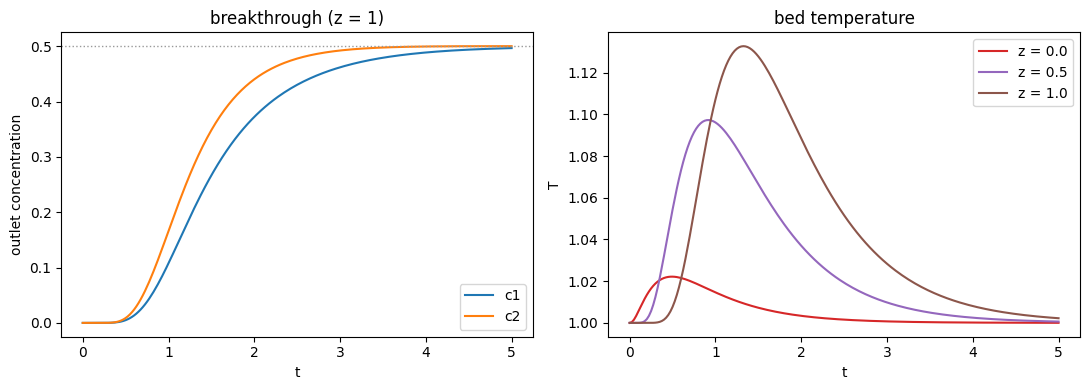

In [4]:
def field_at(S, f, name, zloc, times=None):
    # values of field `name` at z = zloc: (times, values)
    t, z, v = f["t"], f["z"], f[name]
    if isinstance(S, DAESLV):
        nodes = S.semidiscrete_nodes(v)
        col = min(nodes, key=lambda n: abs(n[1][z] - zloc))[0]
        R = S.results_solve
        return R.t, R.x[:, col]
    times = np.linspace(0., T_END, 251) if times is None else times
    return times, np.array([S.eval_solution(v, {t: tk, z: zloc}) for tk in times])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, col in (("c1", "C0"), ("c2", "C1")):
    tt, vv = field_at(S, f, name, 1.)
    ax[0].plot(tt, vv, color=col, label=name)
ax[0].axhline(c0_1, color="0.6", ls=":", lw=1)
ax[0].set_xlabel("t"); ax[0].set_ylabel("outlet concentration"); ax[0].legend(); ax[0].set_title("breakthrough (z = 1)")
for zloc, col in ((0., "C3"), (0.5, "C4"), (1., "C5")):
    tt, vv = field_at(S, f, "T", zloc)
    ax[1].plot(tt, vv, color=col, label="z = %.1f" % zloc)
ax[1].set_xlabel("t"); ax[1].set_ylabel("T"); ax[1].legend(); ax[1].set_title("bed temperature")
plt.tight_layout(); plt.show()

Component 2, the weaker, breaks through first. Equilibrium theory predicts more: between the two
fronts the weaker component **rolls up** above its feed value, displaced by the stronger one. Here
the axial dispersion (a Péclet number $u/D_{ax} = 10$) and the finite uptake rate make the two fronts
overlap, and the plateau that would carry the roll-up is smeared away; a longer or less dispersive bed
shows it. The heat of adsorption is released at the moving front and carried downstream with it, so
the temperature peak grows along the bed, highest at the outlet, and relaxes as the wall takes the
heat away.

## Sensitivities

How strongly do the inventory and the effluent of component 1 depend on its affinity? Both
sensitivity modes are available by name on both solvers; the gradient has one row per degree of
freedom of the inputs -- here the scalar $b_{0,1}$ -- and one column per output. A central difference
checks them.

In [5]:
t0 = time.perf_counter(); S.solve_fsens({b01: 3.}); gf = np.array(S.val_function_gradient())[0]; cpu_f = time.perf_counter() - t0
t0 = time.perf_counter(); S.solve_asens({b01: 3.}); ga = np.array(S.val_function_gradient())[0]; cpu_a = time.perf_counter() - t0
h = 1e-4
S.solve({b01: 3. + h}); fp = np.array(S.val_function())
S.solve({b01: 3. - h}); fm = np.array(S.val_function())
fd = (fp - fm) / (2 * h)
for i, name in enumerate(("inventory", "effluent")):
    print("d %-9s / d b01:  forward %+.6e   adjoint %+.6e   central difference %+.6e" % (name, gf[i], ga[i], fd[i]))
print("forward %.2f s, adjoint %.2f s" % (cpu_f, cpu_a))

d inventory / d b01:  forward +4.124423e-02   adjoint +4.124423e-02   central difference +4.124418e-02
d effluent  / d b01:  forward -4.124422e-02   adjoint -4.124422e-02   central difference -4.124772e-02
forward 1.90 s, adjoint 2.15 s


The two derivatives are **exactly** equal and opposite, and that is a check of the model rather than
a coincidence: what the bed holds at the end and what has left it add up to what was fed,
$\int_0^5 u\,c_{1,
m feed}\,dt$, which does not depend on the affinity. A stronger affinity holds more of
component 1 back. The central difference agrees with the gradients to the noise of differencing two
adaptive solves -- at a tolerance of $10^{-8}$ and a step of $10^{-4}$, about $10^{-4}$ relative.

## The affinity's effect on breakthrough

The outlet curve of component 1 for a few affinities, by re-solving with new input values:

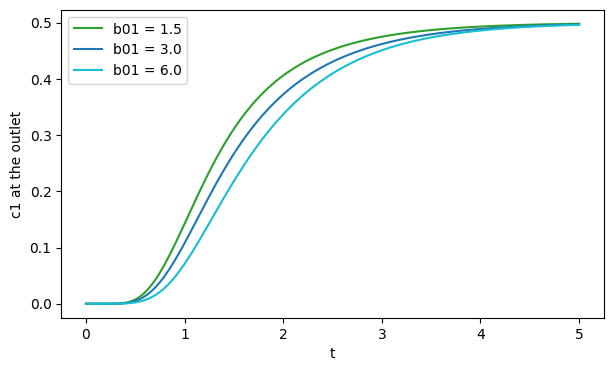

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for bv, col in zip((1.5, 3., 6.), ("C2", "C0", "C9")):
    S.solve({b01: bv})
    tt, vv = field_at(S, f, "c1", 1.)
    ax.plot(tt, vv, color=col, label="b01 = %.1f" % bv)
ax.set_xlabel("t"); ax.set_ylabel("c1 at the outlet"); ax.legend()
plt.show()

A stronger affinity delays component 1's breakthrough: the bed holds more of it before it saturates.

## The other solver

The same declaration on the other solver, and the outputs compared: the two meet to the accuracy of
the space-time collocation in time.

In [7]:
other = "OCFE" if SOLVER == "MoL" else "MoL"
S.solve({b01: 3.}); F1 = np.array(S.val_function())
S2, f2 = build(other)
t0 = time.perf_counter(); S2.solve({f2["b01"]: 3.}); cpu2 = time.perf_counter() - t0
F2 = np.array(S2.val_function())
print("%-5s inventory %.8f  effluent %.8f" % (SOLVER, *F1))
print("%-5s inventory %.8f  effluent %.8f   (%.2f s)" % (other, *F2, cpu2))
print("relative gaps:", ["%.1e" % g for g in np.abs(F1 - F2) / np.abs(F2)])

OCFE: setup done in 2.44 s


MoL   inventory 0.74748419  effluent 1.67751583
OCFE  inventory 0.74748426  effluent 1.67759300   (9.35 s)
relative gaps: ['9.1e-08', '4.6e-05']


Both solvers carry the full model -- nonlinear isotherm, energy balance, Danckwerts inlet -- from
the one declaration. For a single breakthrough simulation the method of lines is the economical
choice: the integrator places its steps where the fronts are. Space-time collocation pays a larger
system for the whole horizon at once, which is what an optimisation over the cycle's operating
policy wants: every state at every time is then a variable the optimiser can see.